# 03 - Baseline: BiLSTM (sigmoid + BCE)
Embedding khởi tạo ngẫu nhiên -> BiLSTM -> [max-pool ; mean-pool] -> dropout -> Linear(28), mỗi nhãn một sigmoid độc lập.
So sánh hai loss: **BCE thường** và **BCE có `pos_weight`** (= #âm/#dương từng nhãn, tính trên train).
Early stopping và chọn cấu hình chỉ dựa trên **val** (Macro-F1 @ 0.5). Test chỉ đánh giá một lần với cấu hình đã chốt.

> **Cách đọc/chạy.** Cần GPU để chạy nhanh (khoảng vài phút; CPU vẫn chạy được nhưng chậm). Đầu ra: xác suất val/test ở `results/preds/bilstm_*.npz`, bảng và hình ở `results/`. Ý nghĩa các chỉ số xem phần giải thích ở đầu `02_tfidf_lr.ipynb`.
> Lưu ý: kết quả GPU có thể lệch nhẹ giữa các lần chạy dù đã cố định seed.

In [1]:
# Khởi tạo: seed, thiết bị (GPU nếu có), dữ liệu và chuẩn hoá văn bản.
# set_seed cố định random/numpy/torch để chạy lại cho kết quả tương tự (GPU vẫn có thể lệch nhẹ vì tính không tất định).
import sys, time, os, random, platform
sys.path.insert(0, '..')
import numpy as np, pandas as pd, torch, torch.nn as nn, collections, re
from torch.nn.utils.rnn import pack_padded_sequence
from src.data import *
from src.preprocess import normalize
from src.metrics import *

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs('../results/preds', exist_ok=True)
print('torch', torch.__version__, '| device', dev, '| python', platform.python_version())

data = load_all()
for s in data: data[s]['clean'] = data[s].text.map(normalize)
Y = {s: label_matrix(data[s]) for s in data}
tiers = label_tiers(Y['train'].sum(0))

torch 2.14.1+cu126 | device cuda | python 3.12.4


C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Từ vựng và mã hoá
Token: từ (`\w+`) hoặc ký tự đơn không phải chữ/khoảng trắng (giữ emoji, dấu câu), hạ chữ thường. Từ vựng chỉ lấy từ train (min_freq = 2); cắt/đệm tới `MAX_LEN` token.

In [2]:
# Từ vựng và mã hoá thành chỉ số nguyên:
# - Tokenize bằng regex (từ hoặc ký tự đặc biệt), hạ chữ thường; từ vựng CHỈ lấy từ train, giữ từ xuất hiện >= MIN_FREQ lần.
# - Chỉ số 0 = <pad> (đệm), 1 = <unk> (từ lạ). encode() cắt/đệm mỗi câu tới MAX_LEN token và trả thêm độ dài thật (lens)
#   để LSTM bỏ qua phần đệm.
# - Dòng print cho biết tỉ lệ token ở val nằm ngoài từ vựng (OOV).
TOKEN = re.compile(r"\b\w+\b|[^\w\s]")
tok = lambda t: TOKEN.findall(t.lower())
MAX_LEN, MIN_FREQ = 100, 2
cnt = collections.Counter(w for t in data['train'].clean for w in tok(t))
itos = ['<pad>', '<unk>'] + [w for w, c in cnt.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
print('kích thước từ vựng:', len(itos), '| tỉ lệ token ngoài từ vựng ở val:',
      round(np.mean([w not in stoi for t in data['val'].clean for w in tok(t)]), 4))

def encode(texts):
    ids = [[stoi.get(w, 1) for w in tok(t)][:MAX_LEN] or [1] for t in texts]
    lens = torch.tensor([len(x) for x in ids])
    X = torch.zeros(len(ids), MAX_LEN, dtype=torch.long)
    for i, x in enumerate(ids): X[i, :len(x)] = torch.tensor(x)
    return X, lens
enc = {s: encode(data[s].clean) for s in data}
T = {s: torch.tensor(Y[s], dtype=torch.float32) for s in Y}

kích thước từ vựng: 5128 | tỉ lệ token ngoài từ vựng ở val: 0.0212


## 2. Mô hình và vòng huấn luyện

In [3]:
# Định nghĩa mô hình BiLSTM, hàm dự đoán và vòng huấn luyện.
# Kiến trúc: Embedding(200) -> dropout -> LSTM hai chiều (ẩn 128 mỗi chiều) -> ghép [max-pool ; mean-pool] theo thời gian -> dropout -> Linear(512 -> 28 logit).
#   Mỗi logit qua sigmoid thành xác suất độc lập của một nhãn (multi-label), nên dùng loss BCE chứ không phải softmax.
# train(): Adam, cắt gradient ở 1.0, early stopping theo Macro-F1 trên val (dừng khi `patience` epoch liên tiếp không cải thiện)
#   và khôi phục trọng số tốt nhất.
class BiLSTM(nn.Module):
    def __init__(self, vocab, emb=200, hid=128, n_out=NUM_LABELS, drop=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=0)
        self.rnn = nn.LSTM(emb, hid, batch_first=True, bidirectional=True)  # hai chiều: đọc câu xuôi và ngược, đầu ra mỗi bước có 2*hid chiều
        self.drop = nn.Dropout(drop); self.fc = nn.Linear(4 * hid, n_out)
    def forward(self, x, lens):
        e = self.drop(self.emb(x))
        out, _ = self.rnn(pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False))  # pack: LSTM bỏ qua phần đệm <pad>
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        mask = (x != 0).unsqueeze(-1)  # mặt nạ các vị trí không phải <pad>
        mx = out.masked_fill(~mask, -1e4).max(1).values  # max-pool theo thời gian (vị trí đệm bị gán số rất nhỏ)
        mean = (out * mask).sum(1) / mask.sum(1).clamp(min=1)  # mean-pool chỉ tính trên token thật
        return self.fc(self.drop(torch.cat([mx, mean], 1)))

@torch.no_grad()  # tắt tính gradient khi dự đoán
def predict(model, split, bs=512):
    model.eval(); X, L = enc[split]; out = []
    for i in range(0, len(X), bs):
        out.append(torch.sigmoid(model(X[i:i+bs].to(dev), L[i:i+bs])).cpu())
    return torch.cat(out).numpy()

def train(pos_weight=None, epochs=30, patience=4, bs=64, lr=1e-3, seed=SEED):
    set_seed(seed)
    model = BiLSTM(len(itos)).to(dev)
    pw = None if pos_weight is None else torch.tensor(pos_weight, dtype=torch.float32, device=dev)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pw)  # BCE trên logit (ổn định số học); pos_weight=None là BCE thường
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    X, L = enc['train']; Yt = T['train']; n = len(X)
    best, best_state, bad, hist = -1, None, 0, []
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(n); tot = 0
        for i in range(0, n, bs):
            idx = perm[i:i+bs]
            loss = lossf(model(X[idx].to(dev), L[idx]), Yt[idx].to(dev))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tot += loss.item() * len(idx)  # một bước tối ưu: xoá gradient, lan truyền ngược, cắt gradient, cập nhật
        f1 = compute_metrics(Y['val'], predict(model, 'val'))['macro_f1']
        hist.append((ep, tot / n, f1))
        if f1 > best: best, bad, best_state = f1, 0, {k: v.clone() for k, v in model.state_dict().items()}  # lưu bản sao trọng số tốt nhất theo val
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return model, time.time() - t0, pd.DataFrame(hist, columns=['epoch', 'train_loss', 'val_macro_f1'])

## 3. So sánh hai loss (chọn theo val)

In [4]:
# So hai loss, chọn theo VAL:
# - 'bce': BCE thường.
# - 'bce_posweight': BCE có pos_weight = (#âm / #dương) của từng nhãn tính trên train, tăng mức phạt khi bỏ sót nhãn hiếm.
# Mỗi cấu hình huấn luyện riêng; bảng `sel` so Macro-F1/Micro-F1/Hamming/LRAP/mAP trên val.
neg_pos = (len(Y['train']) - Y['train'].sum(0)) / Y['train'].sum(0)
runs = {}
for name, pw in [('bce', None), ('bce_posweight', neg_pos)]:
    model, secs, hist = train(pos_weight=pw)
    Pv = predict(model, 'val'); m = compute_metrics(Y['val'], Pv)
    runs[name] = dict(model=model, secs=secs, hist=hist, Pv=Pv)
    print(f'{name:14s} epoch tốt nhất={int(hist.val_macro_f1.idxmax()) + 1:2d}/{len(hist)}  train={secs:5.1f}s  ' +
          '  '.join(f'{k}={v:.4f}' for k, v in m.items() if k != 'subset_acc'))
sel = pd.DataFrame({k: compute_metrics(Y['val'], r['Pv']) for k, r in runs.items()}).T.round(4)
sel['train_s'] = [round(r['secs'], 1) for r in runs.values()]
sel.to_csv('../results/tables/bilstm_loss_val.csv'); sel

bce            epoch tốt nhất=19/23  train=151.4s  macro_f1=0.5164  micro_f1=0.5416  hamming_loss=0.0590  lrap=0.6684  mAP=0.5254


bce_posweight  epoch tốt nhất=18/22  train=168.1s  macro_f1=0.4323  micro_f1=0.4387  hamming_loss=0.1318  lrap=0.6408  mAP=0.5037


,macro_f1,micro_f1,hamming_loss,lrap,mAP,subset_acc,train_s
bce,0.5164,0.5416,0.0590,0.6684,0.5254,0.2004,151.4
bce_posweight,0.4323,0.4387,0.1318,0.6408,0.5037,0.0523,168.1


In [5]:
# Chọn loss có val Macro-F1 cao nhất; lưu lịch sử huấn luyện (loss và val F1 theo epoch) của cả hai cấu hình.
chosen = sel.macro_f1.idxmax(); print('Cấu hình được chọn (theo val Macro-F1):', chosen)
r = runs[chosen]; model = r['model']
runs['bce']['hist'].to_csv('../results/tables/bilstm_history_bce.csv', index=False)
runs['bce_posweight']['hist'].to_csv('../results/tables/bilstm_history_posweight.csv', index=False)

Cấu hình được chọn (theo val Macro-F1): bce


## 4. Dự đoán, lưu xác suất và chỉ số

In [6]:
# Dự đoán và lưu xác suất val/test (.npz) của mô hình đã chọn; tính chỉ số ở ngưỡng 0.5, số tham số, thời gian train;
# lưu bảng kết quả và F1 từng nhãn.
P = {s: predict(model, s) for s in ('val', 'test')}
for s in P: save_preds(f'../results/preds/bilstm_{s}.npz', data[s].id.values, Y[s], P[s])
n_params = sum(p.numel() for p in model.parameters())
res = {s: {**compute_metrics(Y[s], P[s]), **f1_by_tier(Y[s], P[s], tiers)} for s in P}
print(pd.DataFrame(res).T.round(4).T); print('số tham số:', n_params, '| thời gian train (cấu hình chọn):', round(r['secs'], 1), 's')
row = {'model': 'BiLSTM', 'config': f'{chosen}; emb200 hid128 drop0.3 lr1e-3 bs64 maxlen{MAX_LEN} vocab{len(itos)}', 'n_params': n_params,
       'train_seconds': round(r['secs'], 1), **{f'test_{k}': round(v, 4) for k, v in res['test'].items()},
       **{f'val_{k}': round(v, 4) for k, v in res['val'].items() if k in ('macro_f1', 'micro_f1')}}
pd.DataFrame([row]).to_csv('../results/tables/baseline_bilstm.csv', index=False)
pl = per_label_table(Y['test'], P['test'], train_counts=Y['train'].sum(0), tiers=tiers).round(4)
pl.to_csv('../results/tables/perlabel_bilstm_test.csv'); pl.sort_values('f1', ascending=False)

                  val    test
macro_f1       0.5164  0.5115
micro_f1       0.5416  0.5408
hamming_loss   0.0590  0.0590
lrap           0.6684  0.6753
mAP            0.5254  0.5388
subset_acc     0.2004  0.2080
macro_f1_head  0.5548  0.5518
macro_f1_mid   0.4985  0.5019
macro_f1_tail  0.4906  0.4732
số tham số: 1377884 | thời gian train (cấu hình chọn): 151.4 s


,f1,precision,recall,ap,support,train_count,tier
gratitude,0.8056,0.8056,0.8056,0.8853,108,765,mid
amusement,0.7315,0.8000,0.6738,0.7998,374,2868,head
embarrassment,0.7281,0.6860,0.7757,0.8195,107,885,mid
love,0.6689,0.6533,0.6853,0.7350,143,1175,head
sadness,0.6491,0.6954,0.6087,0.7136,345,2785,head
remorse,0.6424,0.6795,0.6092,0.6801,87,707,tail
fear,0.6327,0.6327,0.6327,0.6609,98,745,tail
grief,0.6154,0.6265,0.6047,0.6400,86,747,tail
pride,0.5949,0.6528,0.5465,0.6561,86,774,mid
optimism,0.5725,0.6250,0.5282,0.6210,142,1046,head


## 5. Độ nhạy với ngưỡng (quét trên val; test chỉ báo cáo)

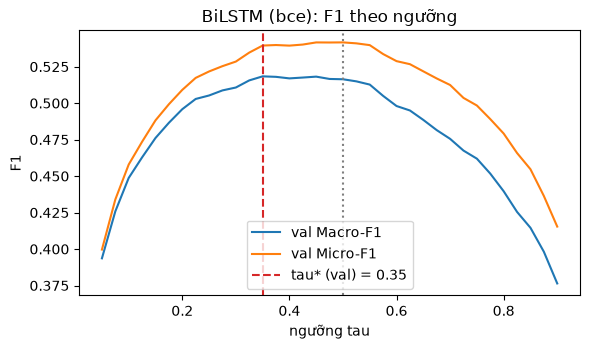

tau*(val)=0.35: val Macro-F1 0.5184 (tau=0.5: 0.5164)
test Macro-F1 tại tau*: 0.5163 (tau=0.5: 0.5115)


In [7]:
# Quét ngưỡng chung tau (0.05 - 0.90): tau* chọn theo val Macro-F1; test chỉ báo cáo tại tau* và tại 0.5 (không dùng test để chọn).
import matplotlib.pyplot as plt
taus = np.round(np.arange(0.05, 0.91, 0.025), 3)
sweep = pd.DataFrame({'tau': taus,
    'val_macro_f1': [compute_metrics(Y['val'], P['val'], t)['macro_f1'] for t in taus],
    'val_micro_f1': [compute_metrics(Y['val'], P['val'], t)['micro_f1'] for t in taus],
    'test_macro_f1': [compute_metrics(Y['test'], P['test'], t)['macro_f1'] for t in taus]})
sweep.to_csv('../results/tables/threshold_sweep_bilstm.csv', index=False)
tau_best = float(sweep.loc[sweep.val_macro_f1.idxmax(), 'tau'])
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(sweep.tau, sweep.val_macro_f1, label='val Macro-F1'); ax.plot(sweep.tau, sweep.val_micro_f1, label='val Micro-F1')
ax.axvline(0.5, ls=':', c='gray'); ax.axvline(tau_best, ls='--', c='C3', label=f'tau* (val) = {tau_best}')
ax.set_xlabel('ngưỡng tau'); ax.set_ylabel('F1'); ax.set_title(f'BiLSTM ({chosen}): F1 theo ngưỡng'); ax.legend(); plt.tight_layout()
plt.savefig('../results/figures/threshold_sweep_bilstm.png'); plt.show()
print(f'tau*(val)={tau_best}: val Macro-F1 {sweep.val_macro_f1.max():.4f} (tau=0.5: {res["val"]["macro_f1"]:.4f})')
print(f'test Macro-F1 tại tau*: {compute_metrics(Y["test"], P["test"], tau_best)["macro_f1"]:.4f} (tau=0.5: {res["test"]["macro_f1"]:.4f})')